[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/su-ntu-ctp/6m-data-3.10-Transformers-Attention-GenAI/blob/main/notebooks/optional_extensions.ipynb)

**Where to run this notebook**

- **Locally (VS Code + Jupyter)**: just open the notebook and pick the `dsai-m3` kernel. Your `.env` file (see `setup.md`) applies the macOS OpenMP fix automatically.
- **Colab (recommended if you don't have a GPU)**: click the badge above, then **Runtime → Change runtime type → T4 GPU**, then run the setup cell below. It clones the repo, installs missing deps, and `cd`s into the right working directory.


In [ ]:
# === Colab-compat setup (no-op when running locally) ===
# This whole IN_COLAB block is skipped when you run locally; it only fires on Colab.
import os, sys

# Detect Colab by checking whether its module was imported into the session.
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # On Colab there is no repo on disk, so we clone it and install the deps Colab lacks.
    REPO_URL = "https://github.com/su-ntu-ctp/6m-data-3.10-Transformers-Attention-GenAI.git"
    REPO_DIR = "/content/6m-data-3.10-Transformers-Attention-GenAI"
    LESSON_DIR = "notebooks"

    if not os.path.exists(REPO_DIR):
        # Clone once; -q keeps the output quiet.
        print(f"Cloning repo into {REPO_DIR} ...")
        os.system(f"git clone -q {REPO_URL} {REPO_DIR}")

    # Move into the notebooks dir so relative paths match the local layout.
    os.chdir(f"{REPO_DIR}/{LESSON_DIR}")
    print(f"Working directory: {os.getcwd()}")

    # Colab has torch + torchvision pre-installed. Install the rest.
    os.system("pip install -q sentence-transformers transformers")
    print("Colab setup done.")

# Threading caps — picked up by .env locally, set explicitly here as a fallback.
# Harmless if already set. (Assigning to _ stops Jupyter from auto-displaying the return value.)
# setdefault only sets the var if it is not already defined, so it never clobbers .env.
_ = os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")   # silence a harmless warning
# (Old OMP/MKL one-thread caps removed — they slowed CPU-only machines.)

# L10 · Optional Extensions

> ⏱️ **~45 min** if you do all three experiments · fully optional · dip into any one on its own

> *Self-study material — three deep dives that build production GenAI skill. Skip any of them; do them in any order.*

This notebook covers:

1. **Prompt engineering** — how the prompt structure shapes LLM behaviour
2. **Sampling deep-dive** — temperature vs top-p, side by side across random seeds
3. **When to fine-tune** — the decision tree for prompt → RAG → fine-tune

## Common setup

In [ ]:
import os
# Env vars below must be set BEFORE importing torch/transformers to take effect.
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'  # allow duplicate OpenMP runtime (macOS libomp conflict)
os.environ['HF_HUB_DISABLE_TELEMETRY'] = '1'  # don't phone home to Hugging Face
os.environ['TRANSFORMERS_VERBOSITY'] = 'error'  # hide noisy info/warning logs

import warnings
warnings.filterwarnings('ignore')  # keep the notebook output clean

# Core imports: timing, the model runtime (torch), and the HF loader classes.
import time
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# (Removed the old one-CPU-thread cap — it made CPU-only machines much slower.)
torch.manual_seed(42)     # fix the RNG so model loading/setup is repeatable
# Use a GPU if one is available, otherwise fall back to CPU:
#   'cuda' = NVIDIA GPU (e.g. Colab T4), 'mps' = Apple Silicon GPU (M1/M2/M3/M4 Macs)
if torch.cuda.is_available():
    DEVICE = 'cuda'
elif torch.backends.mps.is_available():
    DEVICE = 'mps'
else:
    DEVICE = 'cpu'
print(f'Running on: {DEVICE}')

# A small instruction-tuned LLM (360M params) — fast enough to run on CPU.
MODEL = 'HuggingFaceTB/SmolLM2-360M-Instruct'
tokenizer = AutoTokenizer.from_pretrained(MODEL)        # text <-> token ids
llm = AutoModelForCausalLM.from_pretrained(MODEL).to(DEVICE)  # the actual generative model

def generate(messages, max_new_tokens=120, **kwargs):
    # Turn a chat-style messages list into the exact prompt string the model expects.
    # add_generation_prompt=True appends the assistant turn marker so the model continues.
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    # Encode the prompt to token ids (the model's numeric input).
    input_ids = tokenizer(prompt, return_tensors='pt')['input_ids'].to(DEVICE)
    # Generate continuation tokens. **kwargs lets callers pass sampling params (temperature, etc).
    out = llm.generate(input_ids, max_new_tokens=max_new_tokens,
                       pad_token_id=tokenizer.eos_token_id, **kwargs)
    # Slice off the prompt tokens so we keep only the newly generated reply, then decode to text.
    return tokenizer.decode(out[0][input_ids.shape[1]:], skip_special_tokens=True).strip()

print('Model ready.')

---

## Experiment 1 — Prompt engineering: zero-shot vs few-shot vs role-conditioned

The SAME underlying model produces dramatically different output depending on how you frame the prompt. Let's score four prompt patterns on a small labelled test set: classifying customer complaints into a category. One example proves nothing — so we measure on eight.

In [ ]:
# A tiny labelled test set: 8 complaints, 2 per category. One example proves nothing --
# we score every prompt style on all 8 so the comparison is a measurement, not an anecdote.
CATEGORIES = 'shipping, quality, sizing, billing'
test_set = [
    ('The hem is unravelling after one wash.',               'quality'),
    ('My parcel has been stuck in transit for two weeks.',   'shipping'),
    ('I was charged twice for one order.',                   'billing'),
    ('The jeans are far too tight around the waist.',        'sizing'),
    ('The buttons fell off after a day.',                    'quality'),
    ('Delivery came a week late.',                           'shipping'),
    ('I ordered a medium but it fits like an XL.',           'sizing'),
    ('My refund still has not appeared on my card.',         'billing'),
]

# Label definitions -- tell the model what each category MEANS, not just its name.
DEFINITIONS = ('Categories:\n'
               '- shipping: delivery, parcels, lateness, damage in transit\n'
               '- quality: the product is faulty, breaks, tears, fades or falls apart\n'
               '- sizing: fit, too big, too small, measurements\n'
               '- billing: payments, charges, refunds, invoices')
ROLE = f'You are a customer-support triage assistant. Reply with exactly one word: {CATEGORIES}.'
# Few-shot examples, written as real chat turns (user complaint -> assistant label).
EXAMPLES = [('Box arrived crushed and the package was open.', 'shipping'),
            ('Charged twice for the same order.',             'billing'),
            ('Runs about 2 inches small.',                    'sizing'),
            ('The zip broke the first time I used it.',       'quality')]
def example_turns():
    turns = []
    for text, label in EXAMPLES:
        turns += [{'role': 'user', 'content': text}, {'role': 'assistant', 'content': label}]
    return turns

# Four prompt styles. Each takes a complaint and returns a chat message list.
styles = {
    # Zero-shot: just describe the task -- no examples, the model must already "know" it.
    'Zero-shot': lambda c: [{'role': 'user', 'content':
        f'Classify this complaint into ONE of: {CATEGORIES}.\nComplaint: "{c}"\nCategory:'}],
    # Few-shot: worked examples first; the model infers the pattern + output format from them.
    'Few-shot': lambda c: [{'role': 'system', 'content':
        f'Classify each complaint into one of: {CATEGORIES}. Reply with one word.'}]
        + example_turns() + [{'role': 'user', 'content': c}],
    # Role-conditioned: a system prompt sets the persona, strict output rule and label definitions.
    'Role-conditioned': lambda c: [{'role': 'system', 'content': f'{ROLE}\n{DEFINITIONS}'},
                                   {'role': 'user', 'content': c}],
    # Combined: role + definitions in the system prompt, PLUS the few-shot examples.
    'Role + few-shot': lambda c: [{'role': 'system', 'content': f'{ROLE}\n{DEFINITIONS}'}]
        + example_turns() + [{'role': 'user', 'content': c}],
}

for name, build in styles.items():
    preds = [generate(build(c), max_new_tokens=6, do_sample=False) for c, _ in test_set]
    # Count a hit when the reply starts with the right label (ignoring case / trailing '.').
    hits = [p.lower().strip(' .').startswith(gold) for p, (_, gold) in zip(preds, test_set)]
    print(f"=== {name}: {sum(hits)}/{len(test_set)} correct ===")
    for (c, gold), p, ok in zip(test_set, preds, hits):
        print(f"  {'✓' if ok else '✗'} {c[:45]:45s} -> {p[:20]:20s} (gold: {gold})")

**What the scores say:**

- **Zero-shot — 2/8.** The model answered "Billing" to every complaint; it only scored on the two billing ones. A single test case could have made this look fine or terrible by luck.
- **Few-shot — 3/8.** The examples fixed the *format* (clean one-word, lower-case labels) and got the hem complaint right, but the model still leans on two labels.
- **Role-conditioned with label definitions — 4/8.** Telling the model what each category *means* helped most. Notice its raw replies also leak the definitions back ("Shipping: delivery, …") — format control is weaker without examples.
- **Role + few-shot — 4/8.** Clean format *and* the best score, though combining didn't beat role-conditioning alone on this tiny set.

**The bigger lesson:** a 360M model tops out around 50% on a 4-way task a person finds trivial. Prompt structure moves the score, but it can't add capability the model doesn't have — a larger model would do far better with the same prompts. And always **measure on a labelled set**: judged on the hem complaint alone, you'd have ranked these four styles completely differently.

**Three patterns to know:**

- **Zero-shot** — works for tasks the model has clearly seen during training (sentiment, simple classification). Cheap and quick.
- **Few-shot** — show 2-5 examples. The model "learns" the format from the examples. Powerful for unusual formats, sparse classes, or specific phrasing.
- **Role-conditioned** — system prompt sets behaviour. Best when you want concise output, strict format, or a specific persona.

In production you often combine: role-conditioned for the persona + 2-3 few-shot examples for the format.

---

## Experiment 2 — Sampling deep-dive

The same prompt with different sampling parameters produces very different distributions of output. Let's MEASURE how much variation each parameter introduces by sampling the same prompt 3 times (seeds 0, 1, 2).

In [ ]:
# One fixed prompt -- we vary ONLY the sampling parameters below.
prompt = [
    {'role': 'system', 'content': 'You are a witty product copywriter.'},
    {'role': 'user',   'content': 'Write ONE short tagline for a cosy autumn jumper.'}
]

# Each config is (label, generate kwargs). These map to how the next token is picked:
configs = [
    ('Greedy (T=0)', dict(do_sample=False)),                              # always take the most likely token -> deterministic
    ('Low T=0.3',    dict(do_sample=True, temperature=0.3)),             # low temp = sharpen distribution, little variation
    ('Med T=0.7',    dict(do_sample=True, temperature=0.7)),             # moderate randomness, usually the sweet spot
    ('High T=1.5',   dict(do_sample=True, temperature=1.5)),             # high temp = flatten distribution, wild/creative
    ('Top-p=0.9, T=0.7', dict(do_sample=True, temperature=0.7, top_p=0.9)),  # nucleus sampling: only the top 90% prob mass is eligible
]

for name, cfg in configs:
    print(f"\n=== {name} ===")
    # Loop over seeds: with sampling ON, each seed gives a different draw, so this
    # exposes how much run-to-run VARIATION a given setting produces (greedy stays identical).
    for seed in range(3):
        torch.manual_seed(seed)  # reset RNG so each seed is reproducible
        out = generate(prompt, max_new_tokens=30, **cfg)
        print(f"  seed {seed}: {out[:100]}")  # truncate to 100 chars for tidy output

Observations:

- **Greedy is identical across seeds** (no sampling = deterministic) — and repetitive: "stay warm" appears twice in one line.
- **Low temperature (0.3)** already varies between seeds here, but every draw stays on-message — warm, cosy, jumper.
- **Medium temperature (0.7)** gives more varied phrasing while staying coherent — sweet spot for most use.
- **High temperature (1.5)** drifts: seed 0 abandons the tagline format, and seed 2 pitches "a summer dress" for an autumn jumper.
- **Top-p=0.9 with T=0.7** is almost identical to plain T=0.7 here (seeds 0 and 2 match word for word). Top-p trims only the unlikely tail of the distribution — it matters most at high temperature, where that tail gets sampled.

**Production rule of thumb:** start with T=0.7 + top-p=0.9. Lower temperature for code/structured output (T=0.1-0.3). Higher temperature for creative writing (T=1.0+).

---

## Experiment 3 — When to use what: prompt vs RAG vs fine-tune

Three options for adapting an LLM to YOUR task. Each has different costs and best-fit scenarios.

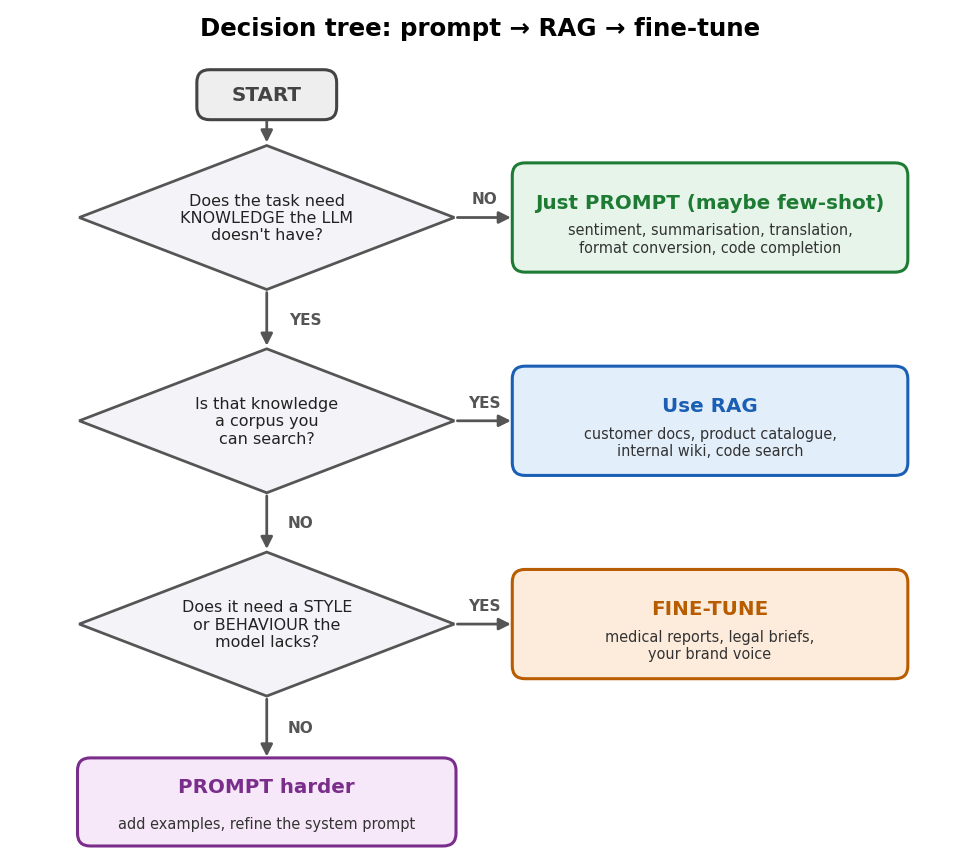

**Cost order, cheap to expensive:**

1. **Prompt engineering** — free, immediate, no infrastructure
2. **Few-shot prompting** — same cost, slightly higher token budget
3. **RAG** — small infra (embeddings + vector store); modest latency hit
4. **Fine-tuning** — significant compute cost ($100-$10K depending on model size and data) + ongoing maintenance
5. **Pretraining from scratch** — almost never the right choice for a product team

**Cost order, in practice:**

For 90% of business GenAI use cases, the answer is *prompt or RAG, not fine-tune*. Fine-tuning is appropriate when:
- You have stable, repeated tasks (not exploratory) — fine-tuning has high setup cost, amortise it
- You need a specific BEHAVIOUR not knowledge (medical-style writing, brand voice, structured output)
- Prompt-only solutions consistently fail evaluation

If you're not sure, **start with prompt + RAG**. You can always fine-tune later. You can't easily unfine-tune a model.

### A specific example

Sarah's catalogue auto-tagger from L08 — would prompting an LLM work?

In [ ]:
# Can a prompt-only LLM tag products by category? Measure it on the REAL catalogue,
# where we already know the right answer for every product.
import pandas as pd
catalogue = pd.read_csv('data/northstar_catalogue.csv')

TAGGER_PROMPT = ('You are a product-category classifier for a clothing and homeware shop. '
                 'Reply with exactly one word from: dress, shirt, trouser, coat, knit, footwear, '
                 'accessory, activewear, home, kids.')
# One worked example per category, as chat turns -- the strongest prompt we found for this model.
TAGGER_EXAMPLES = [
    ('Elegant wrap-style midi dress in deep navy.', 'dress'),
    ('Crisp white button-down shirt in cotton poplin.', 'shirt'),
    ('Slim-fit chinos in stone. Mid-rise, tapered leg.', 'trouser'),
    ('Water-resistant parka with a quilted lining.', 'coat'),
    ('Chunky cable-knit cardigan in cream wool.', 'knit'),
    ('Leather Chelsea boots with a stacked heel.', 'footwear'),
    ('Leather crossbody bag with adjustable strap.', 'accessory'),
    ('High-waisted yoga leggings with a sweat-wicking finish.', 'activewear'),
    ('Scented soy candle in a ceramic pot.', 'home'),
    ("Toddler's striped cotton dungarees.", 'kids'),
]

def tag(description):
    messages = [{'role': 'system', 'content': TAGGER_PROMPT}]
    for text, label in TAGGER_EXAMPLES:
        messages += [{'role': 'user', 'content': text}, {'role': 'assistant', 'content': label}]
    messages.append({'role': 'user', 'content': description})
    # do_sample=False -> greedy, so the classification is deterministic.
    return generate(messages, max_new_tokens=6, do_sample=False).lower().strip(' .')

preds = [tag(d) for d in catalogue['description']]
catalogue['predicted'] = preds
catalogue['correct'] = [p.startswith(c) for p, c in zip(preds, catalogue['category'])]
print(f"Prompt-only tagger accuracy on all {len(catalogue)} products: "
      f"{catalogue['correct'].mean():.0%}   (random guessing among 10 labels = 10%)")
print('\nPredicted label counts:')
print(catalogue['predicted'].value_counts().head(5).to_string())
print('\nA few examples:')
print(catalogue[['name', 'category', 'predicted']].head(8).to_string(index=False))

**Prompt-only tagging fails here — and measuring makes that unarguable.** Even with a role prompt and one worked example per category, the 360M model scores **14%** on the 76 real products, barely above random guessing (10%). It collapses onto two labels — `accessory` and `activewear` — for most of the catalogue. A much larger model (Claude, GPT-4) would do far better; a classifier trained on exactly these 10 labels (like L08's CNN, or a small fine-tuned text classifier) does better still.

**The lesson:** for narrow, repeatable classification, a small model trained on your labels usually beats prompting a general one. You only find out which side of that line you're on by measuring on labelled data — one hand-picked example tells you nothing.

---

## Recap

| Technique | Use when |
|-----------|----------|
| Zero-shot prompt | Task is common, model has seen it during training |
| Few-shot prompt  | Format is specific or class is rare; show 2-5 examples |
| Role-conditioned | You want a persona, strict format, or constrained output |
| Low temperature  | Code, structured output, factual responses |
| Higher temperature | Creative writing, brainstorming |
| RAG              | Need YOUR data; the corpus is searchable |
| Fine-tuning      | Stable repeated task that prompting can't solve reliably |

You've now seen the full GenAI production toolkit. The mathematics took 50 years to invent; the production patterns took five. Picking the right one for YOUR task is the new differentiator.